# Issue #318: historical Beijing SP and proxy admissibility

Executed completeness, provenance, overlap, distortion, and decision review. No outcome or ROI data is read.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
PACKAGE = ROOT / 'results/sp_proxy_audit'
decision = json.loads((PACKAGE / 'decision.json').read_text())
inventory = pd.read_csv(PACKAGE / 'source_inventory.csv')
coverage = pd.read_csv(PACKAGE / 'coverage_by_issue.csv')
overlap = pd.read_csv(PACKAGE / 'overlap_metrics.csv')
exclusions = pd.read_parquet(PACKAGE / 'exclusion_ledger.parquet')
decision

{'conflict_cells': 5991,
 'contract_version': 'BJ-UNIFIED-SP-PROXY-AUDIT-001/v1',
 'failed_thresholds': ['strict 2019-2024 partition thresholds not met',
  'no strict-overlap proxy lane met all frozen thresholds',
  '5991 leakage/time/identity-conflict cells'],
 'observed_metrics': {'graded_cells': 2724201,
  'overlap_cells': 2466,
  'overlap_issues': 1,
  'proxy_accepted_cells': 1916376,
  'strict_accepted_cells': 822},
 'proxy_lane_decisions': [{'partition': 'outside_contract',
   'passes': False,
   'proxy_source_id': 'eu_consensus_fair_odds_268',
   'snapshot_kind': '10h'},
  {'partition': 'outside_contract',
   'passes': False,
   'proxy_source_id': 'eu_consensus_fair_odds_268',
   'snapshot_kind': '1h'},
  {'partition': 'outside_contract',
   'passes': False,
   'proxy_source_id': 'eu_consensus_fair_odds_268',
   'snapshot_kind': 'initial'}],
 'recommendation': 'Do not use historical Beijing SP or its current proxy for value ranking; #319 may proceed probability-only while #218 a

## Source completeness and provenance

In [2]:
display(inventory[['source_id','relative_path','availability','sha256','bytes']])
assert inventory['availability'].eq('PRESENT').all()

,source_id,relative_path,availability,sha256,bytes
0,beidan_xlsm,data/derived/beidan_xlsm/beidan_xlsm.sqlite,PRESENT,7f62079b18b3c028884da92aa8393f5b198246c9d7c32c...,6.872945e+09
1,eu_proxy_backfill,data/derived/bj268/eu_proxy_backfill_v3/candid...,PRESENT,a51bdca8f3b0ef20a31ef606399daea82760a5230a8fc8...,5.445255e+09
2,bj238_materializer,data/derived/bj238_divergence_materializer_v4r3,PRESENT,392f1e6c022efd9ff90e8e37ab4ed4cae8555f2e6131d7...,NaN
3,bj238_source_receipt,docs/research/evidence/bj238/SOURCE_RECEIPT.json,PRESENT,d7adb8cbca9bf5d67f7ae402969bd3dfea171209bb1cad...,8.870000e+02
4,bj216_strict_panel,results/bj216_model_support_panel_v1,PRESENT,eb89f3eeafb0f25946c21edcd4c9b9326217b0b674ea6d...,NaN
5,issue_registry,data/derived/500_bjdc/500_bjdc.sqlite,PRESENT,3c0556abd15a0afcaabd99bcc2c1bd57b43407604b9180...,NaN


## Grade and N7-capacity coverage

,partition,source_id,source_grade,snapshot_kind,issues,vectors,cells,feasible_n7_issues
0,development,beidan_match_features_official_sp,UNUSABLE,historical_unstamped,222,65420,196260,0
1,development,eu_consensus_fair_odds_268,HISTORICAL_PROXY,10h,222,65318,195954,217
2,development,eu_consensus_fair_odds_268,HISTORICAL_PROXY,1h,222,65406,196218,217
3,development,eu_consensus_fair_odds_268,HISTORICAL_PROXY,initial,222,65386,196158,217
4,outside_contract,beidan_match_features_official_sp,UNUSABLE,historical_unstamped,375,95298,285894,0
5,outside_contract,eu_consensus_fair_odds_268,HISTORICAL_PROXY,10h,480,115549,346647,479
6,outside_contract,eu_consensus_fair_odds_268,HISTORICAL_PROXY,1h,480,115597,346791,479
7,outside_contract,eu_consensus_fair_odds_268,HISTORICAL_PROXY,initial,480,115588,346764,479
8,outside_contract,official_500_settlement_sp,UNUSABLE,settlement_import,303,74295,222885,0
9,outside_contract,strict_prospective_216,STRICT_PRE_EVENT,strict_decision_epoch,1,274,822,1


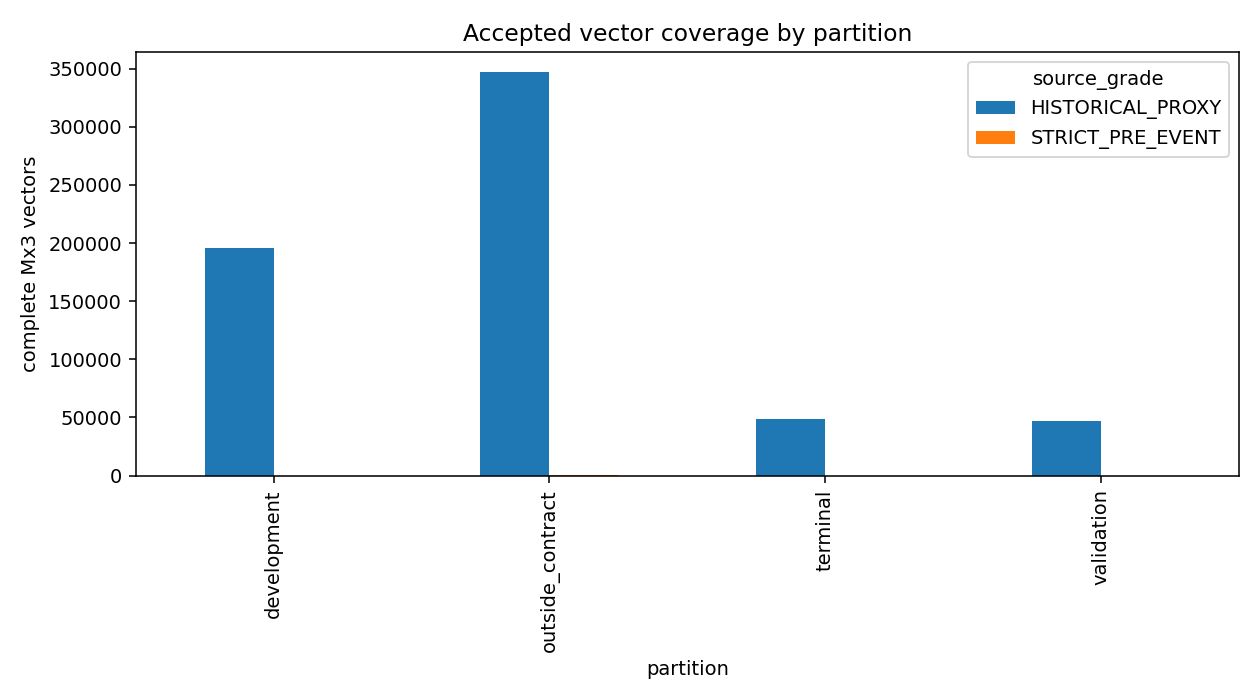

In [3]:
coverage_summary = (coverage.groupby(['partition','source_id','source_grade','snapshot_kind'], dropna=False).agg(issues=('issue_code','nunique'), vectors=('vector_count','sum'), cells=('cell_count','sum'), feasible_n7_issues=('feasible_n7','sum')).reset_index())
display(coverage_summary)
display(Image(filename=str(PACKAGE / 'coverage_by_partition.png')))

## Strict/proxy overlap and distortion

,proxy_source_id,snapshot_kind,partition,issue_count,fixture_count,price_bias_issue_equal,price_bias_p025,price_bias_p50,price_bias_p975,median_abs_log_price_error_issue_equal,...,top7_jaccard_p50,top7_jaccard_p975,q_distortion_issue_equal,q_distortion_p025,q_distortion_p50,q_distortion_p975,abs_relative_q_distortion_issue_equal,abs_relative_q_distortion_p025,abs_relative_q_distortion_p50,abs_relative_q_distortion_p975
0,eu_consensus_fair_odds_268,10h,outside_contract,1,274,-0.428900,-0.428900,-0.428900,-0.428900,0.271845,...,0.0,0.0,-4.690802,-4.690802,-4.690802,-4.690802,0.811852,0.811852,0.811852,0.811852
1,eu_consensus_fair_odds_268,1h,outside_contract,1,274,-0.425155,-0.425155,-0.425155,-0.425155,0.285300,...,0.0,0.0,-4.719038,-4.719038,-4.719038,-4.719038,0.828136,0.828136,0.828136,0.828136
2,eu_consensus_fair_odds_268,initial,outside_contract,1,274,-0.431884,-0.431884,-0.431884,-0.431884,0.274781,...,0.0,0.0,-4.707067,-4.707067,-4.707067,-4.707067,0.800880,0.800880,0.800880,0.800880


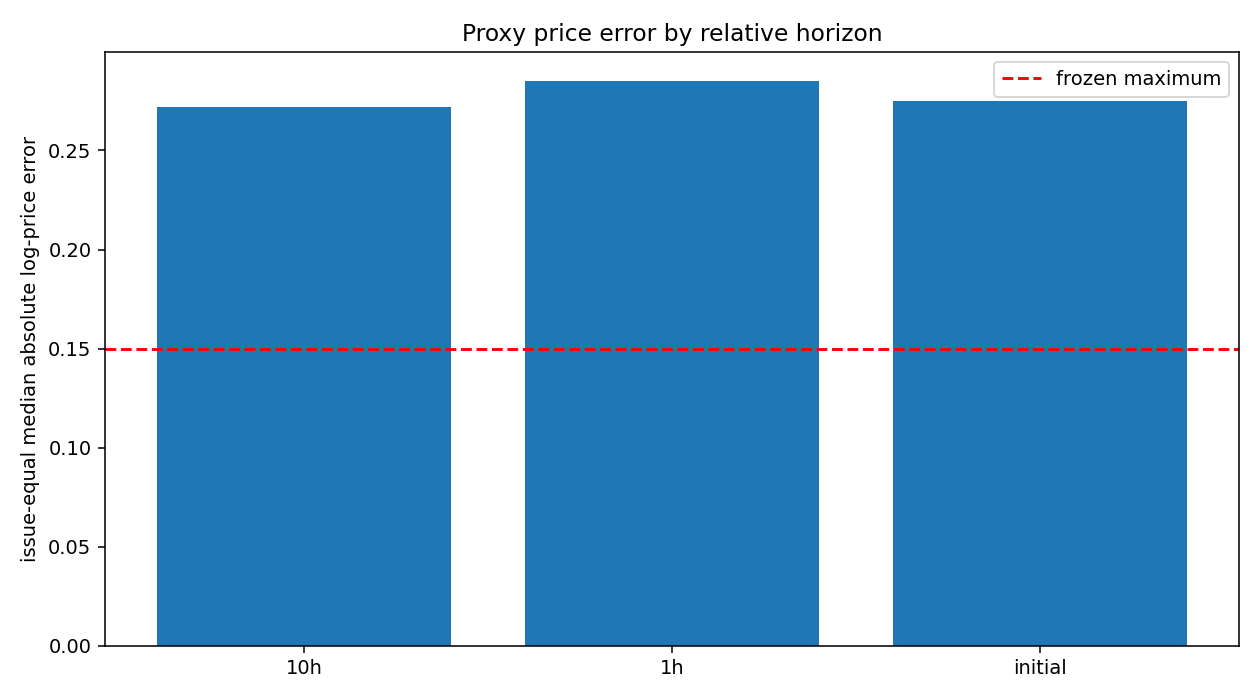

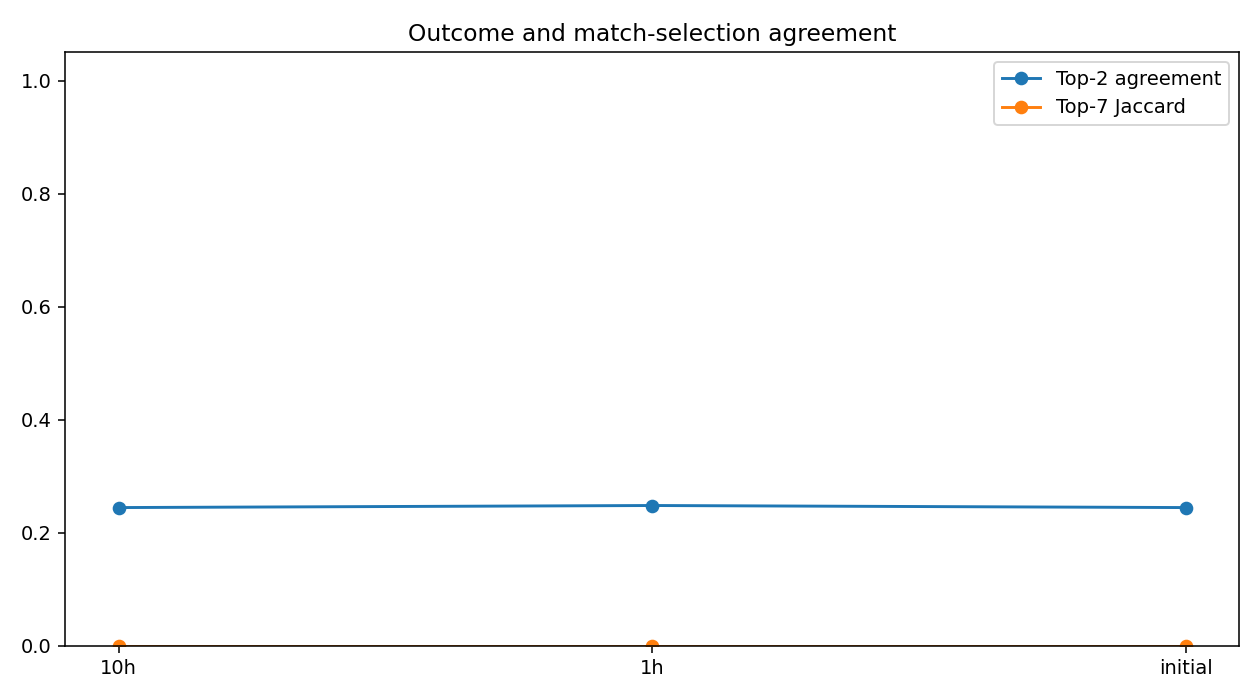

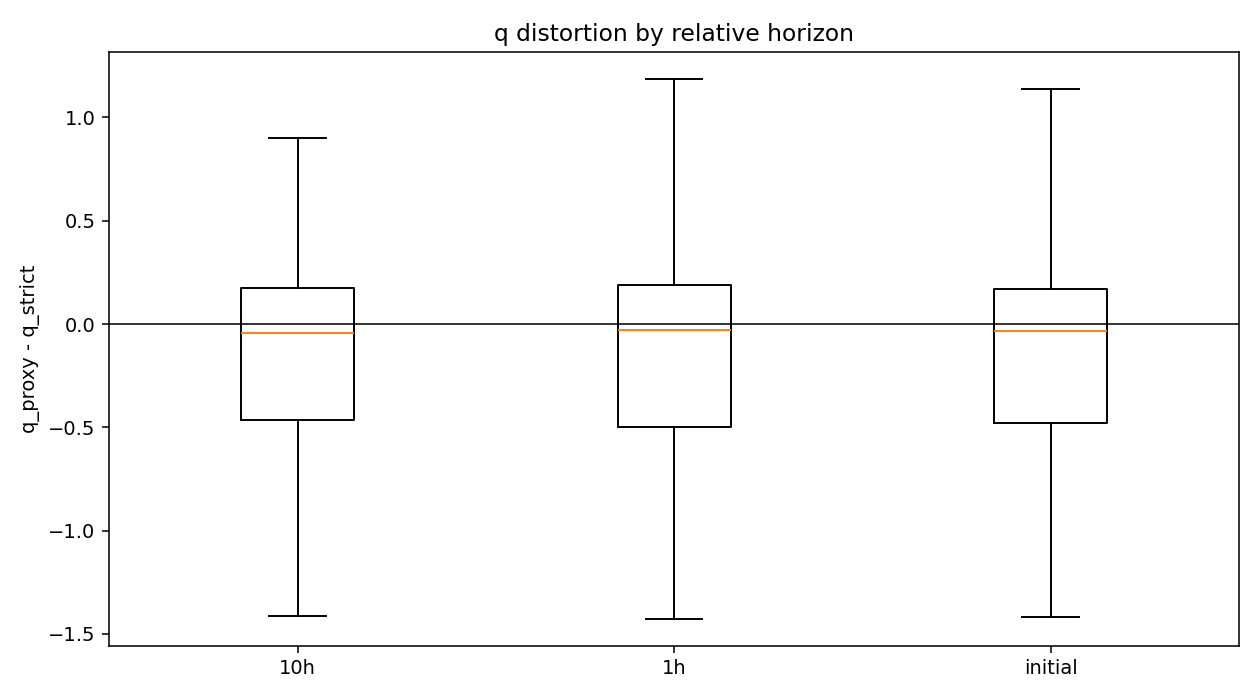

In [4]:
display(overlap)
for name in ['price_error_by_horizon.png','top2_top7_agreement.png','q_distortion.png']:
    display(Image(filename=str(PACKAGE / name)))

## Exclusion reconstruction

In [5]:
display(exclusions)

,source_id,snapshot_kind,exclusion_reason,cell_count,vector_count,issue_count,denominator_note
0,beidan_match_features_official_sp,historical_unstamped,TIMESTAMP_UNPROVEN,578127,192709,701,graded Mx3 cells
1,official_500_settlement_sp,settlement_import,POST_KICKOFF,215511,71837,298,graded Mx3 cells
2,official_500_settlement_sp,settlement_import,SETTLEMENT_ONLY,7374,2458,6,graded Mx3 cells
3,strict_prospective_216,strict_decision_epoch,IDENTITY_MISMATCH,5988,1996,28,graded Mx3 cells
4,strict_prospective_216,strict_decision_epoch,POST_DECISION,3,1,1,graded Mx3 cells


## Frozen terminal decision

In [6]:
summary = {
    'terminal_disposition': decision['terminal_disposition'],
    'observed_metrics': decision['observed_metrics'],
    'failed_thresholds': decision['failed_thresholds'],
    'recommendation': decision['recommendation'],
}
summary

{'terminal_disposition': 'NO_CAUSAL_PRICE_SUPPORT',
 'observed_metrics': {'graded_cells': 2724201,
  'overlap_cells': 2466,
  'overlap_issues': 1,
  'proxy_accepted_cells': 1916376,
  'strict_accepted_cells': 822},
 'failed_thresholds': ['strict 2019-2024 partition thresholds not met',
  'no strict-overlap proxy lane met all frozen thresholds',
  '5991 leakage/time/identity-conflict cells'],
 'recommendation': 'Do not use historical Beijing SP or its current proxy for value ranking; #319 may proceed probability-only while #218 accumulates strict prospective support.'}